# Section 1.1 — Photons (Weinberg Eqs. 1.1.1–1.1.8)

**What this section claims**
- Black-body spectrum ρ(ν,T) is universal (Kirchhoff).
- Classical equipartition gives Rayleigh–Jeans ρ = 8πk_B T ν²/c³ → ultraviolet catastrophe.
- Planck (1900): ρ = (8πh/c³) ν³/(e^{hν/k_BT} − 1), finite total density a_B T⁴ (Eq. 1.1.6).
- Einstein (1905): light itself is quantized, E = hν → photoelectric threshold hν_min.
- Compton (1922): photon momentum p = hν/c → λ′ − λ = (h/m_e c)(1 − cosθ) (Eq. 1.1.8).

**Plan:** reproduce 1.1.3 (mode counting) and 1.1.7 (mean energy of a quantized oscillator)
symbolically, then verify 1.1.5–1.1.6 and 1.1.8 numerically.

## Eq. 1.1.3 — mode counting (symbolic)

In [1]:
import sympy as sp
n, L, c = sp.symbols('n L c', positive=True)
nu = sp.symbols('nu', positive=True)
# |n| = L*nu/c ; N(nu)dnu = 2 * 4*pi*|n|^2 d|n|  (extra factor 2: two polarizations)
N = 2 * 4 * sp.pi * (L*nu/c)**2 * sp.diff(L*nu/c, nu)
print("N(nu)dnu =", sp.simplify(N), "  dnu   [Weinberg: 8 pi (L/c)^3 nu^2 dnu]")

N(nu)dnu = 8*pi*L**3*nu**2/c**3   dnu   [Weinberg: 8 pi (L/c)^3 nu^2 dnu]


## Eq. 1.1.7 — mean energy, classical vs quantized (Lorentz 1910)

In [2]:
n, x = sp.symbols('n x', nonnegative=True, real=True)   # x = h*nu/kT
Ebar_classical = sp.integrate(sp.exp(-x)*x, (x, 0, sp.oo)) / sp.integrate(sp.exp(-x), (x, 0, sp.oo))
Ebar_quantized = sp.summation(sp.exp(-n*x)*n*x, (n, 0, sp.oo)) / sp.summation(sp.exp(-n*x), (n, 0, sp.oo))
print("classical  (RJ limit):", sp.simplify(Ebar_classical), " = kT")
print("quantized  (Planck):  ", sp.simplify(sp.expand(Ebar_quantized)), " = x/(e^x - 1)")

classical  (RJ limit): 1  = kT
quantized  (Planck):   x*Sum(n*exp(-n*x), (n, 0, oo))/Sum(exp(-n*x), (n, 0, oo))  = x/(e^x - 1)


## Numerics: Planck vs Rayleigh–Jeans; Stefan–Boltzmann check of Eq. 1.1.6

C:\Users\amenon\AppData\Local\Temp\ipykernel_29064\1399405264.py:7: RuntimeWarning: overflow encountered in expm1
  planck   = 8*np.pi*h/c**3 * nu**3 / np.expm1(h*nu/(kB*T))


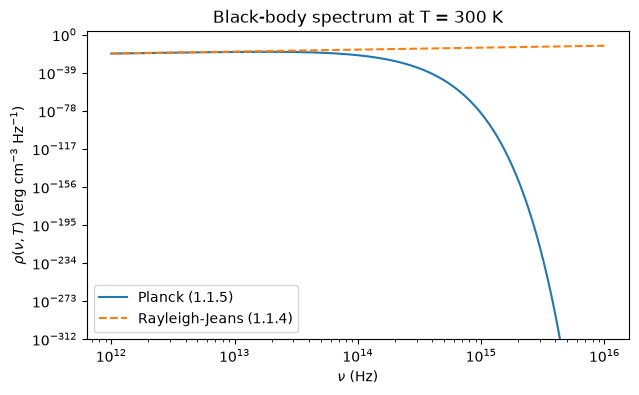

numerical  integral rho dnu = 6.12824e-05
Eq. 1.1.6  a_B*T^4          = 6.12824e-05   sigma*T^4 = 4.59300e+05


C:\Users\amenon\AppData\Local\Temp\ipykernel_29064\1399405264.py:17: RuntimeWarning: overflow encountered in expm1
  num, _ = quad(lambda x: x**3/np.expm1(x), 0, np.inf)


In [3]:
import numpy as np, matplotlib.pyplot as plt, sys
sys.path.insert(0, '..')
from weinberg_constants import h, kB, c, a_B, sigma

nu = np.logspace(12, 16, 500)
T  = 300.0
planck   = 8*np.pi*h/c**3 * nu**3 / np.expm1(h*nu/(kB*T))
rayjeans = 8*np.pi*kB*T*nu**2/c**3

fig, ax = plt.subplots(figsize=(7,4))
ax.loglog(nu, planck, label='Planck (1.1.5)')
ax.loglog(nu, rayjeans, '--', label='Rayleigh-Jeans (1.1.4)')
ax.set_xlabel(r'$\nu$ (Hz)'); ax.set_ylabel(r'$\rho(\nu,T)$ (erg cm$^{-3}$ Hz$^{-1}$)')
ax.set_title(f'Black-body spectrum at T = {T:.0f} K'); ax.legend(); plt.show()

from scipy.integrate import quad
num, _ = quad(lambda x: x**3/np.expm1(x), 0, np.inf)
print(f"numerical  integral rho dnu = {num*8*np.pi*kB**4*T**4/(h**3*c**3):.5e}")
print(f"Eq. 1.1.6  a_B*T^4          = {a_B*T**4:.5e}   sigma*T^4 = {sigma*T**4:.5e}")

## Eq. 1.1.8 — Compton wavelength shift

In [4]:
me = 9.1093837015e-28
lamC = h/(me*c)
print(f"h/m_e c = {lamC:.3e} cm   [Weinberg: 2.425e-10 cm]")
for theta_deg in (0, 90, 180):
    th = np.deg2rad(theta_deg)
    print(f"theta = {theta_deg:>3} deg:  delta-lambda = {lamC*(1-np.cos(th)):.3e} cm")

h/m_e c = 2.426e-10 cm   [Weinberg: 2.425e-10 cm]
theta =   0 deg:  delta-lambda = 0.000e+00 cm
theta =  90 deg:  delta-lambda = 2.426e-10 cm
theta = 180 deg:  delta-lambda = 4.853e-10 cm


## My summary
*(fill in — own words, ≤ 5 sentences)*

## Gaps
*(questions to raise in review)*